| Nama              | NRP        |
|-------------------|------------|
| Muhammad Dayyan Ghazanfar Latief         | 5054241036     |

<center><strong>Pemrosesan Bahasa Natural</strong><br />
<strong><font color="blue">Rekayasa Kecerdasan Artifisial</font></strong><br />
</center>

<strong>Outline pertemuan minggu ke-5</strong><br />
<li> Pendahuluan Klasifikasi </li>
<li> K-NN, Naive Byaes, Decision Tree, SVM </li>
<li> Visualisasi dengan boxplot </li>


<p><img alt="" src="figures/56_Supervised VS unsupervised.png" style="height:500px; width:1153px" /></p>

### K-Nearest Neighbour (K-NN)
- Classifier yang paling sederhana
- Dapat digunakan untuk permaslaahn klasifikasi dan regresi

<strong> Kelebihan: </strong>
- Efisien untuk data berukuran besar
- Sederhana, mudah diimplementasikan
- Mudah dimodikasi (perhitungan jarak)
- Menangani data multiclass dengan mudah

<strong> Kekurangan: </strong>
- Semakin besar data semakin lambat performanya (menghitung NN)
- Memerlukan jumlah K optimal
- Tidak cocok untuk imbalance data

<p><img alt="" src="figures/6_kNN.JPG" style="height:300px; width:711px" /></p>

In [2]:
# load data pickle dari 20newsgroups yang didapat dari pertemuan 4
import pickle
import os

src_name = "20newsgroups.pickle"
with open(src_name, 'rb') as fin:
    data = pickle.load(fin)

docs = [doc for doc in data.data]
label = data.target

print('DONE!')

DONE!


In [3]:
# preprocessing
import re
from nltk import sent_tokenize
from nltk import word_tokenize

def preprocess(doc):
    sents = sent_tokenize(doc)
    sents_tok = list() # tokenisasi kalimat
    for s in sents:
        s = s.strip().lower() # case folding dan menghilangkan new line
        s = s.replace("\n", " ") # menggantikan \n dengan spasi
        s = re.sub(r'[^a-zA-Z0-9 ]', ' ', s) # menghapus simbol
        s = re.sub(' +', ' ', s) # menghapus repetitive space

        sents_tok.append(s)

    return " ".join(sents_tok)

docs_clear = list()
for d in docs:
    docs_clear.append(preprocess(d))

In [4]:
# representasi vektor dengan VSM-TFIDF
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(max_df=0.95, min_df=2)
X = tfidf_vectorizer.fit_transform(docs_clear)
print(X.shape)

(1653, 10721)


In [5]:
print(len(label))
print(len(docs_clear))
print(len(X.getnnz(1)))
print(X.shape)

1653
1653
1653
(1653, 10721)


In [6]:
# Cleaning noise
# Hapus label yang memiliki row = 0 pada tfidf-nya
# Hapus row yang memiliki nilai 0
Y = label[X.getnnz(1)>0]
X_clear = X[X.getnnz(1)>0]

# Hapus dokumen yang memiliki nilai row 0
docs_nonzero = list()
for i, d in enumerate(X.getnnz(1)>0):
    if d:
        docs_nonzero.append(docs_clear[i])

print(X_clear.shape, len(Y), len(docs_nonzero))

(1590, 10721) 1590 1590


In [7]:
# Membagi data menjadi dua yaitu data training dan data testing
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X_clear, Y, test_size=.3, random_state=8989)
print(X_train.shape, X_test.shape)

(1113, 10721) (477, 10721)


In [8]:
# KNN menggunakan scikit-learn library
# http://scikit-learn.org/stable/modules/neighbors.html
from sklearn import neighbors

K = 10
weights = 'distance'
kNN = neighbors.KNeighborsClassifier(n_neighbors=K, weights=weights)
kNN.fit(X_train, Y_train)
print('Done!')

Done!


In [9]:
# Prediksi dengan KNN
Y_knn = kNN.predict(X_test)

In [10]:
# Evaluasi dengan akurasi
from sklearn.metrics import accuracy_score

accuracy_score(Y_test, Y_knn)

0.7274633123689728

<h3 id="Latihan:"><font color="blue">Latihan 1:</font></h3>

<ul>
    <li> Mengapa perlu dilakukan data splitting (training dan testing)?</li>
    <li> Apakah rasio splitting berpengaruh pada performa dari model? </li>
    <li> Cobalah beberapa model dengan merubah nilai dari parameter K, berapakah nilai K yang paling optimal? </li>

In [11]:
# Kerjakan latihan 1 pada cell berikut ini

### Jawaban Latihan 1

**1. Mengapa perlu dilakukan data splitting (training dan testing)?** 
* *Data splitting* merupakan hal yang sangat penting untuk dilakukan untuk memastikan model tidak hanya menghafal data saat dilatih (mencegah overfitting), tetapi juga terbukti akurat saat memprediksi data baru yang belum pernah ia lihat sebelumnya.

**2. Apakah rasio splitting berpengaruh pada performa dari model?** \
Ya, rasio pemisahan data sangat berpengaruh terhadap performa model:
* Jika **rasio data train cenderung kecil**, model akan kekurangan informasi untuk mempelajari pola dengan baik, sehingga rentan mengalami underfitting dan hasil prediksinya menjadi kurang akurat.
* Jika **rasio data train terlalu besar**, model mungkin belajar dengan sangat baik, namun hasil evaluasinya menjadi kurang valid dan tidak reliabel karena jumlah data ujinya terlalu sedikit untuk mengukur performa aslinya.


Mulai mencari nilai K yang optimal...
Akurasi untuk K=1 : 0.8323
Akurasi untuk K=2 : 0.8323
Akurasi untuk K=3 : 0.8239
Akurasi untuk K=4 : 0.8218
Akurasi untuk K=5 : 0.8029
Akurasi untuk K=6 : 0.7925
Akurasi untuk K=7 : 0.7820
Akurasi untuk K=8 : 0.7568
Akurasi untuk K=9 : 0.7568
Akurasi untuk K=10 : 0.7275
Akurasi untuk K=11 : 0.7191
Akurasi untuk K=12 : 0.7002
Akurasi untuk K=13 : 0.7002
Akurasi untuk K=14 : 0.6939
Akurasi untuk K=15 : 0.6792
Akurasi untuk K=16 : 0.6688
Akurasi untuk K=17 : 0.6688
Akurasi untuk K=18 : 0.6541
Akurasi untuk K=19 : 0.6583
Akurasi untuk K=20 : 0.6604

Kesimpulan: Nilai K yang paling optimal adalah K = 1 dengan akurasi maksimal sebesar 0.8323


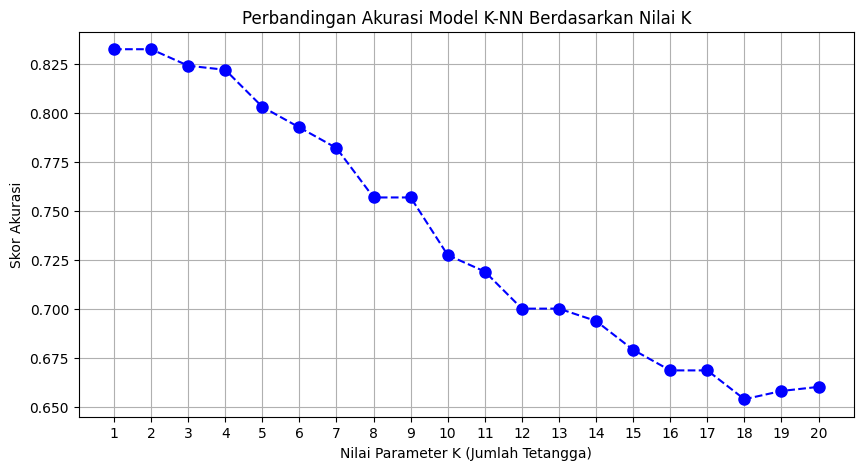

In [12]:
import matplotlib.pyplot as plt

k_values = range(1, 21)
accuracies = []

print("Mulai mencari nilai K yang optimal...")

for k in k_values:
    # 1. Inisialisasi model K-NN dengan parameter K yang sedang diuji
    kNN_model = neighbors.KNeighborsClassifier(n_neighbors=k, weights='distance')
    
    # 2. Melatih model menggunakan data training
    kNN_model.fit(X_train, Y_train)
    
    # 3. Melakukan prediksi pada data testing
    Y_pred = kNN_model.predict(X_test)
    
    # 4. Menghitung skor akurasi dan menyimpannya ke dalam list
    acc = accuracy_score(Y_test, Y_pred)
    accuracies.append(acc)
    print(f"Akurasi untuk K={k} : {acc:.4f}")

# Menemukan nilai K dengan tingkat akurasi tertinggi
optimal_k = k_values[accuracies.index(max(accuracies))]
print(f"\nKesimpulan: Nilai K yang paling optimal adalah K = {optimal_k} dengan akurasi maksimal sebesar {max(accuracies):.4f}")

# Visualisasi hasil evaluasi 
plt.figure(figsize=(10, 5))
plt.plot(k_values, accuracies, marker='o', linestyle='dashed', color='blue', markersize=8)
plt.title('Perbandingan Akurasi Model K-NN Berdasarkan Nilai K')
plt.xlabel('Nilai Parameter K (Jumlah Tetangga)')
plt.ylabel('Skor Akurasi')
plt.xticks(k_values)
plt.grid(True)
plt.show()

### Naive Bayes Classifier

Metode klasifikasi dengan pendekatan probabilitas yang didasarkan pada teorema <strong>Bayes</strong>. Berasumsi bahwa semua fitur adalah independen dan memiliki kontribusi yang sama.

<p><img alt="" src="figures/naive_bayes.png" style="width: 400px ; height: 220px" /></p>

<strong>Dimana:</strong>
- x : fitur
- c : kelas
- P(c|x) : Probabilitas kelas c diberikan x sebagai fitur

<strong> Kelebihan:</strong>
- Cepat dan mudah diimplementasikan
- Cocok untuk multiclass
- Dapat bekerja dengan baik untuk data berdimensi tinggi (high-dimensional data)

<strong> Kekurangan:</strong>
- Asumsi bahwa semua fitur independen terkadang tidak sesuai dengan real-life data

In [13]:
# Menggunakan data sebelumnya
# Naive bayes menggunakan library scikit-learn
# http://scikit-learn.org/stable/modules/naive_bayes.html
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
nbc = gnb.fit(X_train.toarray(), Y_train)
Y_nbc = nbc.predict(X_test.toarray())

accuracy_score(Y_test, Y_nbc)

0.870020964360587

### Decision Tree

Decision tree menggunakan rule-based (if else condition) pada sebuah tree untuk membangan sebuah model. Decision tree dapat dipergunakan untuk categorical ataupun numerical data.

<p><img alt="" src="figures/6_DT.png" style="height:336px; width:904px" /></p>

<p> Contoh: </p>
<p><img alt="" src="figures/6_DT_meme.png" style="height:342px; width:460px" /></p>

<strong>Kelebihan:</strong>
- Mudah untuk dipahami, cocok untuk visualisasi
- Dapat digunakan untuk categorical maupun numerical data
- non-parametric model
- Robust terhadap outliers dan missing values

<strong>Kekurangan:</strong>
- Sering overfit





In [14]:
# Decision Tree dengan library scikit-learn
#http://scikit-learn.org/stable/modules/tree.html
from sklearn import tree

DT = tree.DecisionTreeClassifier()
DT = DT.fit(X_train, Y_train)
Y_DT = DT.predict(X_test)

accuracy_score(Y_test, Y_DT)

0.6624737945492662

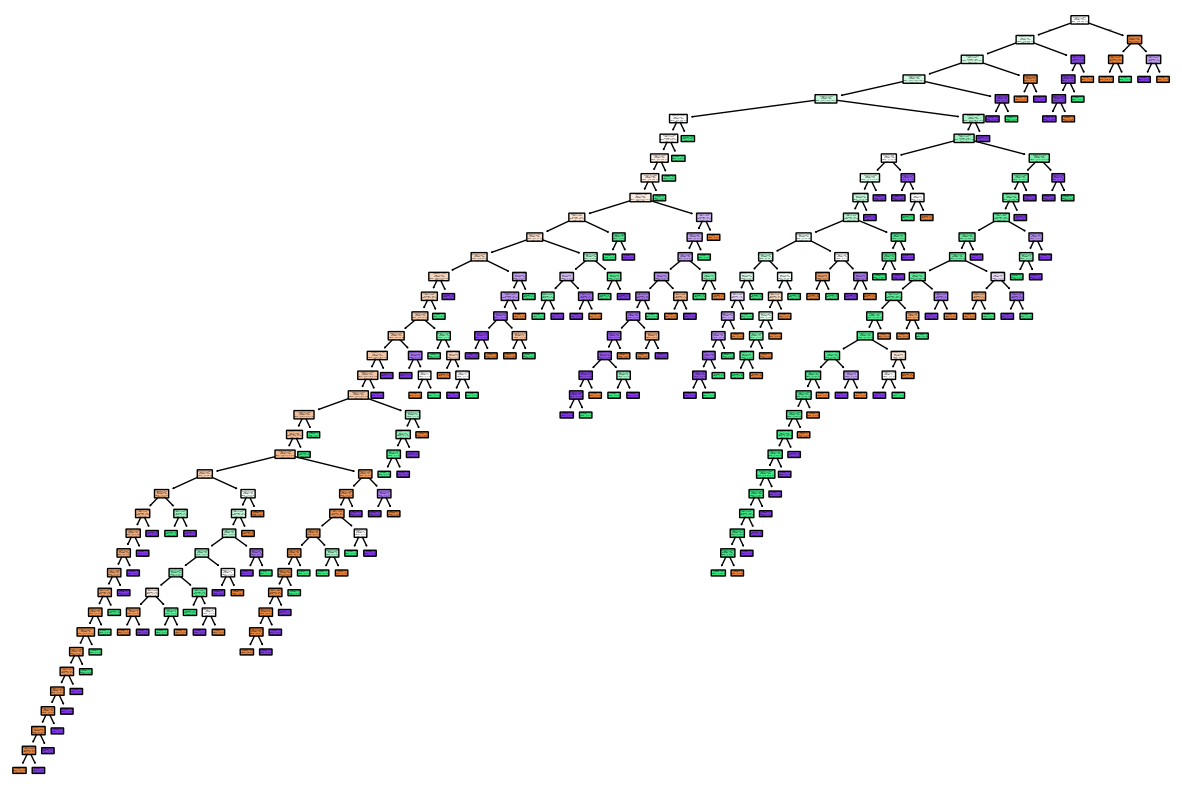

In [15]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(15, 10))

plot_tree(DT, 
          filled=True, 
          rounded=True, 
          class_names=True, # Mengubahnya menjadi class label asli jika memungkinkan
          feature_names=X_train.columns if hasattr(X_train, 'columns') else None)

plt.show()

### Random Forest

<p><img alt="" src="figures/5_RandomForest.png" style="width: 592px; height: 444px;" /></p>

<p>Terdiri dari beberapa decision tree. Merupakan ensamble algorithm yang mengambil hasil dari beberapa decision tree. </p>

<strong>Kelenihan:</strong>
- Robust terhadap outlier
- Dapat bekerja dengan baik pada non-linear data
- Dapat menurunkan risiko overfitting
- Dapat bekerja dengan efisien pada data set yang besar

<strong>Kekurangan:</strong>
- Bias ketika dipergunakan untuk categorical variabel
- lambat

In [16]:
# Random Forest
# http://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
from sklearn.ensemble import RandomForestClassifier

RandomForest = RandomForestClassifier()
RandomForest.fit(X_train, Y_train)
Y_RF = RandomForest.predict(X_test)
accuracy_score(Y_test, Y_RF)

0.7777777777777778

### Support Vector Machine (SVM)

<p><img alt="" src="figures/6_SVM.jpg" style="height: 262px ; width: 232px" /><img alt="" src="figures/svm_opt.png" style="width: 300px; height: 106px;" /></p>
<p>SVM melakukan plotting data ke dalam n-dimensi. Klasifikasi dilakukan dengan mencari hyper-plane yg memisahkan dua kelas.</p>

<h4> SVM kernel </h4>
<p> SVM kernel digunakan untuk data yang bersifat non-linear. Data yang bersifat non-linear tidak dapat dipisahkan dengan menggunakan garis lurus seperti pada data linear. Untuk mengatasi permasalahan tersebut digunakan <strong>kernel trick</strong>. Kernel trick mentransformasikan data ke dalam dimensi yg lebih tinggi agar lebih mudah dipisahkan.</p>

<strong> Beberapa kernel SVM:</strong>
- Linear
- Polynomial
- RBF
- Sigmoid


<h4>SVM multiclass</h4>

<p><img alt="" src="figures/6_SVM_Ova.jpg" style="height:314px; width:432px" /></p>

<strong>Kelebihan:</strong>
- Dapat bekerja dengan efektif pada dataset berukuran kecil
- Memiliki performa yang baik untuk data berdimensi tinggi
- Relatif efisien dalam penggunaan memori

<strong>Kekurangan:</strong>
- Kurang cocok untuk dataset berukuran besar
- Kurang efektif untuk data yang memiliki banyak noise

In [17]:
# SVM
# http://scikit-learn.org/stable/modules/svm.html
from sklearn import svm

dSVM = svm.SVC(decision_function_shape='ovo') # one versus one SVM
dSVM.fit(X_train, Y_train)
Y_SVM = dSVM.predict(X_test)
accuracy_score(Y_test, Y_SVM)

0.8721174004192872

In [18]:
# Menggunakan kernel trick
# Default kernel dari fungsi SVM pada scikit learn adalah 'RBF'
list_kernel = ['linear', 'poly', 'rbf', 'sigmoid']
for kernel in list_kernel:
    dSVM = svm.SVC(kernel=kernel, gamma='auto')
    dSVM.fit(X_train, Y_train)
    y_SVM = dSVM.predict(X_test)
    print(kernel, ':', accuracy_score(Y_test, y_SVM))

linear : 0.8805031446540881
poly : 0.36268343815513626
rbf : 0.36268343815513626
sigmoid : 0.36268343815513626


### Cross Validation

<p>Cross validation dipergunakan untuk memvalidasi hasil dari suatu model, memastikan objektifitas dari hasil. </p>

<p><img alt="" src="figures/6_Cross_validation.png" style="height:274px; width:485px" /></p>

In [19]:
# Cross validation
# http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html
from sklearn.model_selection import cross_val_score
import time

svm_ = svm.SVC(kernel='linear')
start = time.time()
scores_svm = cross_val_score(svm_, X_clear, Y, cv=10) # perhatikan sekarang kita menggunakan seluruh data
timepros = time.time() - start

print("Accuracy SVM: %0.2f (+/- %0.2f), Waktu = %0.3f detik" % (scores_svm.mean(), scores_svm.std() * 2, timepros))

Accuracy SVM: 0.91 (+/- 0.04), Waktu = 21.890 detik


In [20]:
# Bagaimana dengan k-NN ?
mulai = time.time()
scores_kNN = cross_val_score(kNN, X_clear, Y, cv=10) # perhatikan sekarang kita menggunakan seluruh data
waktu = time.time() - mulai
# Interval Akurasi 95 CI
print("Accuracy k-NN: %0.2f (+/- %0.2f), Waktu = %0.3f detik" % (scores_kNN.mean(), scores_kNN.std() * 2, waktu))

Accuracy k-NN: 0.75 (+/- 0.09), Waktu = 0.208 detik


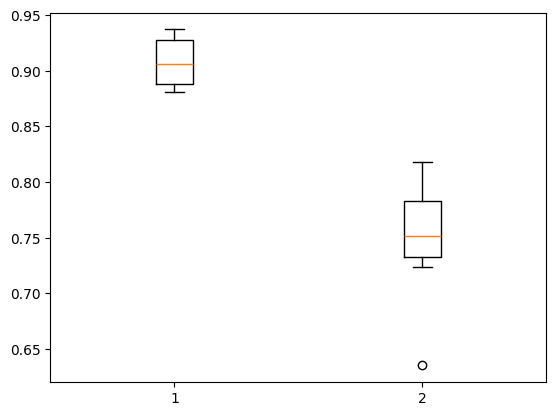

In [21]:
# Visualisasi hasil dengan boxplot
# Buat BoxPlotnya
import matplotlib.pyplot as plt
import numpy as np

Data = [scores_svm, scores_kNN]
L = ['SVM', 'kNN']

fig, ax = plt.subplots()

# Creating plot
plt.boxplot(Data)

# show plot
plt.show()

### Bagaimana jika ingin menggunakan word embedding sebagai representasi vektornya?

In [22]:
# Melakukan persiapan dokumen
# yang digunakan sebagai data adalah docs_nonzero
doc_gensim = [word_tokenize(d) for d in docs_nonzero]

In [23]:
# membuat Word Embeddingnya
from gensim.models import FastText

N = len(doc_gensim)
dim = 300 # Jumlah neurons = ukuran vektor = jumlah kolom
model_FT = FastText(doc_gensim, vector_size=dim, window=5, min_count=1, workers=-1)

In [24]:
# NOTE:
# tidak dapat langsung menggunakan hasil dari word embedding
# representasi vektor embedding adalah representasi per kata
# harus mengkonversikan dari word embedding ke dalam vektor space
# dokumen x words
def we2vsm(model_we, data_we):
    N = len(data_we)
    L = model_we.vector_size
    vsm_we = np.empty([N, L], dtype=np.float64) # inisialisasi matriks
    for i,d in enumerate(data_we):
        tmp = np.zeros([1, L], dtype=np.float64)
        count = 0
        for t in d:
            try:
                tmp += model_we.wv.__getitem__([t])
                count += 1
            except:
                pass
        if count>0:
            vsm_we[i] = tmp/count
    return vsm_we

In [25]:
vsm_we = we2vsm(model_FT, doc_gensim)
vsm_we.shape

(1590, 300)

#### Setelah memiliki bentuk representasi dokumen, langkah selanjutnya adalah melakukan proses klasifikasi seperti yang telah dicontohkan sebelumnya

<h3 id="Latihan:"><font color="blue">Latihan 2:</font></h3>

- Lakukan klasifikasi dengan representasi yang telah diperoleh dari proses word embedding (vsm_we) dengan berbagai metode (knn, desicion tree, random forest, naive bayes, dan VSM)
- Visualisasikan hasilnya
- Bandingkan hasilnya dengan representasi dari VSM-TFIDF

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [ ]:
# Klasifikasi 

X_we_train, X_we_test, Y_we_train, Y_we_test = train_test_split(vsm_we, Y, test_size=0.3, random_state=8989)

models = {
    "K-NN": KNeighborsClassifier(n_neighbors=10, weights='distance'),
    "Decision Tree": DecisionTreeClassifier(random_state=8989),
    "Random Forest": RandomForestClassifier(random_state=8989),
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(random_state=8989)
}

we_accuracies = {}
tfidf_accuracies = {}

print("--- Proses Evaluasi Model Sedang Berjalan ---")
for name, model in models.items():
    model.fit(X_we_train, Y_we_train)
    Y_pred_we = model.predict(X_we_test)
    we_accuracies[name] = accuracy_score(Y_we_test, Y_pred_we)
    
    # TF-IDF
    if name == "Naive Bayes":
        model.fit(X_train.toarray(), Y_train)
        Y_pred_tfidf = model.predict(X_test.toarray())
    else:
        model.fit(X_train, Y_train)
        Y_pred_tfidf = model.predict(X_test)
        
    tfidf_accuracies[name] = accuracy_score(Y_test, Y_pred_tfidf)

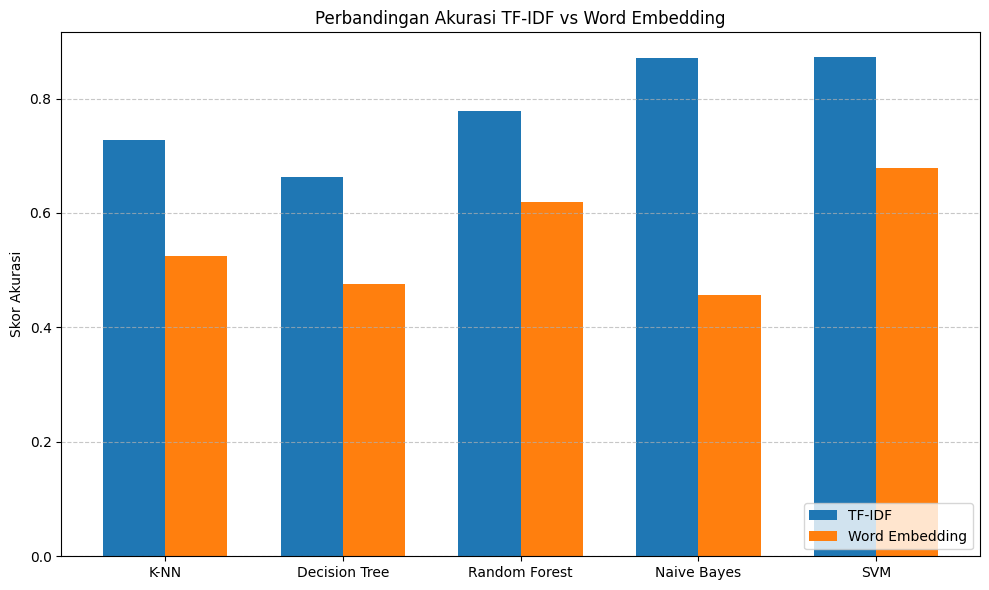

In [29]:
# Visualisasi Hasil Evaluasi

labels = list(models.keys())
we_scores = list(we_accuracies.values())
tfidf_scores = list(tfidf_accuracies.values())

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, tfidf_scores, width, label='TF-IDF', color='#1f77b4')
rects2 = ax.bar(x + width/2, we_scores, width, label='Word Embedding', color='#ff7f0e')

ax.set_ylabel('Skor Akurasi')
ax.set_title('Perbandingan Akurasi TF-IDF vs Word Embedding')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend(loc='lower right')
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [32]:
# Perbandingan Hasil dengan Cross Validation

from sklearn.model_selection import cross_val_score

cv_folds = 5
we_cv_scores = {}
tfidf_cv_scores = {}

for name, model in models.items():
    # 1. Cross Validation untuk Word Embedding
    scores_we = cross_val_score(model, vsm_we, Y, cv=cv_folds, scoring='accuracy')
    we_cv_scores[name] = scores_we.mean() # Mengambil rata-rata dari ke-5 pengujian
    
    # 2. Cross Validation untuk TF-IDF 
    if name == "Naive Bayes":
        scores_tfidf = cross_val_score(model, X_clear.toarray(), Y, cv=cv_folds, scoring='accuracy')
    else:
        scores_tfidf = cross_val_score(model, X_clear, Y, cv=cv_folds, scoring='accuracy')
        
    tfidf_cv_scores[name] = scores_tfidf.mean()

print("RANGKUMAN HASIL CROSS VALIDATION:")
print("="*75)
print(f"{'Model':<15} | {'TF-IDF (CV)':<13} | {'Word Embed (CV)':<16} | {'Selisih':<10}")
print("-" * 75)
for name in models.keys():
    diff = we_cv_scores[name] - tfidf_cv_scores[name]
    sign = "+" if diff > 0 else ""
    print(f"{name:<15} | {tfidf_cv_scores[name]:.4f}        | {we_cv_scores[name]:.4f}           | {sign}{diff:.4f}")
print("="*75)

RANGKUMAN HASIL CROSS VALIDATION:
Model           | TF-IDF (CV)   | Word Embed (CV)  | Selisih   
---------------------------------------------------------------------------
K-NN            | 0.7302        | 0.5214           | -0.2088
Decision Tree   | 0.6371        | 0.4667           | -0.1704
Random Forest   | 0.8031        | 0.6031           | -0.2000
Naive Bayes     | 0.8667        | 0.4679           | -0.3987
SVM             | 0.8931        | 0.6912           | -0.2019
